In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/rishidamarla/heart-disease-prediction/Heart_Disease_Prediction.csv


In [3]:
# ================================
# 📌 1. Import Libraries
# ================================
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib
import os

# Set style for plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
tf.random.set_seed(42)
np.random.seed(42)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [4]:
# ================================
# 📌 2. Load Dataset
# ================================
dataset = pd.read_csv("/kaggle/input/datasets/rishidamarla/heart-disease-prediction/Heart_Disease_Prediction.csv")

print("Dataset Shape:", dataset.shape)
print("\nFirst 5 rows:")
display(dataset.head())

print("\nTarget Distribution:")
print(dataset.iloc[:, -1].value_counts())

# Basic info
dataset.info()

Dataset Shape: (270, 14)

First 5 rows:


,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence



Target Distribution:
Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null   

In [5]:
# ================================
# 📌 3. Data Preprocessing
# ================================
# Encode categorical columns if any
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in dataset.columns:
    if dataset[col].dtype == 'object':
        dataset[col] = le.fit_transform(dataset[col])

# Split features and target
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

# Convert to float
X = X.astype(np.float32)
y = y.astype(np.float32)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (270, 13)
Target shape: (270,)


In [6]:
# ================================
# 📌 4. Train-Test Split & Scaling
# ================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Save scaler for Streamlit app
joblib.dump(scaler, "scaler.pkl")

print("✅ Data successfully split and scaled")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

✅ Data successfully split and scaled
Training samples: 216
Testing samples: 54


In [7]:
# ================================
# 📌 5. Build Enhanced ANN Model
# ================================
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    
    tf.keras.layers.Dense(256, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),
    
    tf.keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    
    tf.keras.layers.Dense(64, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    
    tf.keras.layers.Dense(32, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),
    
    tf.keras.layers.Dense(16, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.BatchNormalization(),
    
    # Output Layer
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1776010030.334714      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1776010030.341582      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,345 (192.75 KB)

 Trainable params: 48,353 (188.88 KB)

 Non-trainable params: 992 (3.88 KB)

In [8]:
# ================================
# 📌 6. Callbacks + Training
# ================================
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'best_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Save final model
model.save("final_model.keras")
print("✅ Model saved as final_model.keras")

Epoch 1/100


I0000 00:00:1776010045.163991     136 service.cc:152] XLA service 0x7a9f4c00a020 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776010045.164028     136 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1776010045.164032     136 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1776010045.849649     136 cuda_dnn.cc:529] Loaded cuDNN version 91002


1/7 ━━━━━━━━━━━━━━━━━━━━ 44s 7s/step - accuracy: 0.4375 - loss: 1.0029

I0000 00:00:1776010049.263614     136 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 634ms/step - accuracy: 0.4666 - loss: 0.9679
Epoch 1: val_accuracy improved from -inf to 0.55556, saving model to best_model.keras
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 845ms/step - accuracy: 0.4696 - loss: 0.9609 - val_accuracy: 0.5556 - val_loss: 0.9584 - learning_rate: 0.0010
Epoch 2/100
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5312 - loss: 0.8158
Epoch 2: val_accuracy did not improve from 0.55556
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5411 - loss: 0.7746 - val_accuracy: 0.5556 - val_loss: 0.8582 - learning_rate: 0.0010
Epoch 3/100
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5312 - loss: 0.6381
Epoch 3: val_accuracy did not improve from 0.55556
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6491 - loss: 0.5844 - val_accuracy: 0.5370 - val_loss: 0.7874 - learning_rate: 0.0010
Epoch 4/100
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6875 - loss: 0.7060
Epoch 4: val_accuracy did not improve from 0.55556
7/7 ━━━━━━━━━━━━━━━━

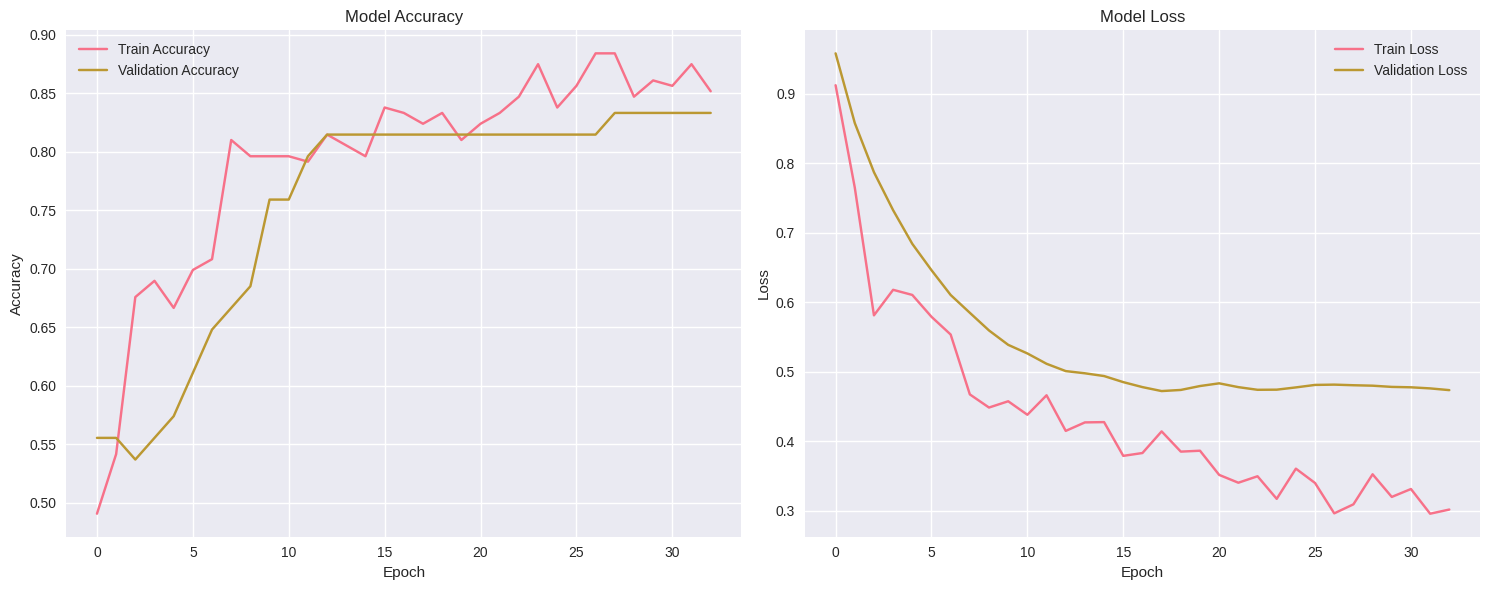

In [9]:
# ================================
# 📌 7. Plot Training History
# ================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Accuracy Plot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss Plot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 404ms/step
Final Test Accuracy: 83.33333333333334

Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.73      0.83        30
         1.0       0.74      0.96      0.84        24

    accuracy                           0.83        54
   macro avg       0.85      0.85      0.83        54
weighted avg       0.86      0.83      0.83        54



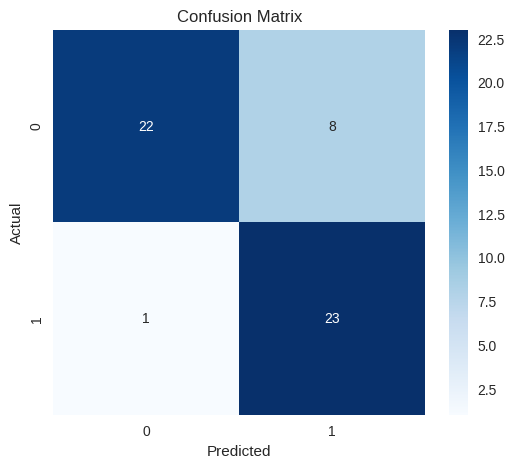

In [10]:
# ================================
# 📌 8. Final Evaluation
# ================================
# Load best model if available
if os.path.exists('best_model.keras'):
    best_model = tf.keras.models.load_model('best_model.keras')
else:
    best_model = model

# Predictions
y_pred_prob = best_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Metrics
print("Final Test Accuracy:", accuracy_score(y_test, y_pred)*100)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [11]:
# ================================
# 📌 9. Save Files for Streamlit
# ================================
joblib.dump(scaler, "scaler.pkl")
model.save("final_model.keras")

print("🎉 All files saved successfully!")
print("Files ready for your Streamlit app:")
print("   → final_model.keras")
print("   → scaler.pkl")

🎉 All files saved successfully!
Files ready for your Streamlit app:
   → final_model.keras
   → scaler.pkl
